# Aprendizaje automático en geociencias

El aprendizaje automático (machine learning) es el conjunto de métodos que permiten a un computador aprender patrones a partir de datos, sin que se le programen explícitamente las reglas. La definición clásica de {cite:t}`mitchell1997` lo dice con precisión: un programa aprende de la experiencia E con respecto a una clase de tareas T y una medida de desempeño P si su desempeño en las tareas de T, medido por P, mejora con la experiencia E. En un problema de susceptibilidad por deslizamientos, por ejemplo, la tarea es predecir si una celda del terreno es inestable, la experiencia es un inventario de deslizamientos con sus variables (pendiente, litología, lluvia) y el desempeño se mide con la exactitud o el área bajo la curva ROC sobre datos que el modelo no ha visto.

El aprendizaje automático hace parte de la inteligencia artificial y se traslapa con la estadística, la minería de datos y la ciencia de datos. La minería de datos busca descubrir patrones y conocimiento en conjuntos de datos grandes; la ciencia de datos abarca todo el ciclo, desde la formulación de la pregunta y la recolección de los datos hasta la comunicación de los resultados. En geociencias su uso creció con la disponibilidad de datos (sensores remotos, redes de monitoreo, inventarios, modelos de elevación) y hoy se aplica a la cartografía de susceptibilidad, la clasificación de imágenes, la predicción de caudales, la sismología o la exploración de recursos {cite}`reichstein2019,merghadi2020`.

## Tipos de aprendizaje

En el aprendizaje supervisado cada ejemplo tiene una variable respuesta conocida y el modelo aprende la relación entre las variables de entrada (predictores, variables explicativas o features) y la respuesta. Si la respuesta es continua, como un caudal o una resistencia, el problema es de regresión; si es categórica, como deslizamiento o no deslizamiento, es de clasificación. En el aprendizaje no supervisado no hay respuesta: el objetivo es encontrar estructura en los datos, como grupos de muestras geoquímicas parecidas o combinaciones de variables que resumen la mayor parte de la variabilidad. Hay además formas intermedias, como el aprendizaje semisupervisado, con pocas muestras etiquetadas y muchas sin etiquetar, y el aprendizaje por refuerzo, en el que un agente aprende a actuar a partir de recompensas.

## Explicar o predecir

Un modelo puede construirse con dos propósitos distintos {cite}`shmueli2010,breiman2001two`. Un modelo explicativo busca entender cómo cambia la respuesta $Y$ en función de los predictores $X_1, \dots, X_p$: qué variables están asociadas con la respuesta, con qué signo y magnitud, y si la relación es lineal. En este caso la función estimada $\hat f$ no puede ser una caja negra, porque interesa su forma. Un modelo predictivo, en cambio, busca predecir $Y$ con la menor incertidumbre posible para nuevos casos, y la forma de $\hat f$ importa menos que su desempeño. La estadística clásica se ha concentrado en el primer propósito y el aprendizaje automático en el segundo, pero en geociencias casi siempre se necesitan los dos: un mapa de susceptibilidad debe predecir bien y también ser coherente con los procesos físicos que conocemos {cite}`karpatne2017`.

En ambos casos se supone que los datos provienen de una relación de la forma

$$Y = f(X) + \varepsilon,$$

donde $\varepsilon$ es un error aleatorio. El error de una predicción $\hat Y = \hat f(X)$ tiene una parte reducible, que se debe a que $\hat f$ no es igual a $f$ y se puede disminuir con mejores modelos o más datos, y una parte irreducible, la varianza de $\varepsilon$, que se debe a variables no medidas o a variabilidad intrínseca del fenómeno y que ningún modelo puede eliminar {cite}`james2021`.

## Asociación, correlación y causalidad

Que dos variables estén asociadas no significa que una cause la otra. La asociación indica que una variable aporta información sobre la otra; la correlación es un tipo particular de asociación que mide tendencias crecientes o decrecientes; la causalidad es una relación más fuerte en la que la variable causa es responsable, al menos en parte, del efecto. La causalidad no se puede inferir solo del análisis de datos: hay que suponerla o demostrarla con argumentos externos al análisis estadístico, como un experimento controlado o un mecanismo físico conocido.

El caso más común de asociación sin causalidad es una variable de confusión que afecta a las dos. La celda siguiente lo simula con un ejemplo geológico: en una cuenca, la elevación controla tanto la lluvia anual (por efecto orográfico) como la densidad de deslizamientos (por la pendiente, que aumenta con la elevación). La lluvia y los deslizamientos aparecen correlacionados aunque, en esta simulación, la lluvia no tiene ningún efecto directo sobre los deslizamientos.

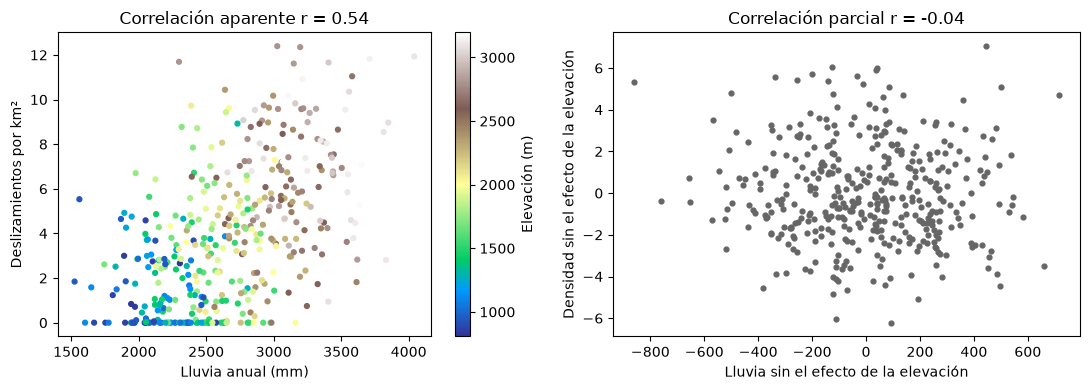

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(1)

n = 400
elevacion = rng.uniform(800, 3200, n)                       # m
lluvia = 1500 + 0.6 * elevacion + rng.normal(0, 250, n)      # mm/año, efecto orográfico
pendiente = 8 + 0.008 * elevacion + rng.normal(0, 4, n)      # grados
densidad = np.clip(0.4 * (pendiente - 15) + rng.normal(0, 2, n), 0, None)   # deslizamientos/km², solo depende de la pendiente

r_bruta = np.corrcoef(lluvia, densidad)[0, 1]
# correlación parcial: se elimina el efecto lineal de la elevación en ambas variables
res_ll = lluvia - np.polyval(np.polyfit(elevacion, lluvia, 1), elevacion)
res_de = densidad - np.polyval(np.polyfit(elevacion, densidad, 1), elevacion)
r_parcial = np.corrcoef(res_ll, res_de)[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(lluvia, densidad, c=elevacion, cmap='terrain', s=12)
ax[0].set_xlabel('Lluvia anual (mm)'); ax[0].set_ylabel('Deslizamientos por km²')
ax[0].set_title(f'Correlación aparente r = {r_bruta:.2f}')
fig.colorbar(sc, ax=ax[0], label='Elevación (m)')
ax[1].scatter(res_ll, res_de, s=12, color='0.4')
ax[1].set_xlabel('Lluvia sin el efecto de la elevación'); ax[1].set_ylabel('Densidad sin el efecto de la elevación')
ax[1].set_title(f'Correlación parcial r = {r_parcial:.2f}')
plt.tight_layout(); plt.show()

Al controlar por la elevación, la correlación entre lluvia y deslizamientos desaparece. En datos reales la lluvia sí detona deslizamientos, pero el ejemplo muestra que un modelo que encuentra la lluvia como predictor importante no demuestra por sí solo que la lluvia sea la causa: puede estar actuando como sustituto de otra variable.

## El ciclo de un proyecto de aprendizaje automático

Un proyecto sigue un ciclo iterativo. Se formula la pregunta y la hipótesis, y se decide si el propósito es explicar o predecir. Se recolectan y preparan los datos: limpieza, valores faltantes, valores atípicos, transformación y escalado. Se exploran con estadística descriptiva y gráficas. Se seleccionan o construyen las variables. Se dividen los datos para entrenar y evaluar, se ajustan varios modelos y se eligen sus hiperparámetros con validación cruzada. Se evalúa el modelo final con datos independientes y métricas adecuadas, se interpreta y, por último, se comunica o se pone en operación. Cada capítulo de este libro corresponde a uno de estos pasos.

No hay un algoritmo que sea el mejor para todos los problemas: es el teorema de "no hay almuerzo gratis" (no free lunch). Un modelo funciona bien cuando sus supuestos se ajustan a la estructura del problema, y por eso la práctica habitual es comparar varios modelos con un protocolo de validación riguroso. La celda siguiente da una primera muestra de ese protocolo: ajusta dos modelos muy distintos a datos sintéticos de deslizamientos y compara su exactitud en datos de entrenamiento y de prueba.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

def inventario(n=2000, semilla=0):
    """Inventario sintético: pendiente (°), lluvia (mm), distancia a cauces (m) y si hubo deslizamiento."""
    r = np.random.default_rng(semilla)
    pend = r.gamma(4, 6, n)
    lluv = r.normal(2500, 500, n)
    dist = r.exponential(250, n)
    eta = -6 + 0.12 * pend + 0.0012 * lluv - 0.004 * dist
    p = 1 / (1 + np.exp(-eta))
    return np.column_stack([pend, lluv, dist]), (r.random(n) < p).astype(int)

X, y = inventario()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
for nombre, modelo in [('regresión logística', LogisticRegression(max_iter=1000)),
                       ('árbol de decisión sin límite', DecisionTreeClassifier(random_state=0))]:
    modelo.fit(X_tr, y_tr)
    print(f'{nombre:30s} exactitud entrenamiento {modelo.score(X_tr, y_tr):.3f}   prueba {modelo.score(X_te, y_te):.3f}')
print(f'Proporción de deslizamientos: {y.mean():.2f}')

regresión logística            exactitud entrenamiento 0.796   prueba 0.778
árbol de decisión sin límite   exactitud entrenamiento 1.000   prueba 0.707
Proporción de deslizamientos: 0.31


El árbol sin límite memoriza los datos de entrenamiento (exactitud cercana a 1) pero predice peor que la regresión logística en los datos de prueba: está sobreajustado. La regresión logística, cuya forma coincide con la del proceso que generó los datos, generaliza mejor. Este contraste entre lo que un modelo aprende y lo que generaliza es el tema del capítulo {doc}`05_SesgoVarianza`.

## Para profundizar

El capítulo 2 de {cite}`james2021` presenta los conceptos de este capítulo con mucha claridad. {cite:t}`shmueli2010` y {cite:t}`breiman2001two` discuten la diferencia entre explicar y predecir. Para el papel del aprendizaje automático en las ciencias de la Tierra, ver {cite:t}`reichstein2019` y {cite:t}`karpatne2017`.